# Hebrew synthetic-voice pilot EDA

One fixed Hebrew sentence per selected stock model/voice. This is a controlled voice inventory, not a 20-hour corpus or a representative demographic survey.

**Keep three distinct concepts separate:** provider voice labels; unvalidated audio-model estimates of perceived presentation/age; and human listening ratings. A synthetic voice has no biological age or sex. Perceived age bins are casting impressions from a few seconds, not measured ages. Unknown and conflicting assessments stay visible. Models sharing a provider/voice identifier are dependent observations.

Generation uses the OpenRouter speech API. Automated review is blind to the intended sentence and to model/voice IDs. No audio is generated and no API calls are made when executing this notebook.

In [1]:
from pathlib import Path
import json, hashlib, sys, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT=Path.cwd(); BASE=ROOT/'synthetic_pilot'; ANALYSIS=BASE/'analysis'; FIG=ANALYSIS/'figures'
FIG.mkdir(parents=True,exist_ok=True)
planned=pd.read_csv(BASE/'planned_samples.csv',keep_default_na=False)
generated=pd.read_csv(BASE/'manifest.csv',keep_default_na=False)
reviews=pd.read_csv(BASE/'automated_review.csv',keep_default_na=False)
assert planned.sample_id.is_unique and generated.sample_id.is_unique and reviews.sample_id.is_unique
df=planned.merge(generated.drop(columns=[c for c in generated if c in planned and c!='sample_id']),on='sample_id',how='left',validate='one_to_one')
df=df.drop(columns=['language_qc_status'],errors='ignore').merge(reviews,on='sample_id',how='left',validate='one_to_one',suffixes=('','_review'))
for c in ['technical_qc_pass','language_qc_pass']:
    df[c]=df[c].map(lambda x:x is True or str(x).lower()=='true')
df['pilot_automatic_qc_pass']=df.technical_qc_pass & df.language_qc_pass
for c in ['duration_s','rms_dbfs','peak','near_fullscale_fraction','quiet_fraction_45dbfs','energy_dynamic_range_db','normalized_character_error_rate','presentation_confidence','age_confidence']:
    df[c]=pd.to_numeric(df[c],errors='coerce')
df['presentation_for_summary']=df.presentation_for_summary.fillna('uncertain').replace('','uncertain')
df['age_for_summary']=df.age_for_summary.fillna('uncertain').replace('','uncertain')
df['raw_age_for_summary']=df.age_for_summary
age_estimator_uninformative=bool(df.review_status.eq('reviewed').sum()>=20 and df.loc[df.review_status.eq('reviewed'),'age_for_summary'].nunique()<=1)
if age_estimator_uninformative: df['age_for_summary']='uniform_estimator_not_validated'
df['nominal_prompt_wpm']=60*df.text.str.split().str.len()/df.duration_s
def export(frame,name): frame.to_csv(ANALYSIS/(name+'.csv'),index=False,encoding='utf-8-sig')
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG/(name+'.png'),dpi=150,bbox_inches='tight'); plt.show(); plt.close()
def markdown_table(frame):
    result=['| '+' | '.join(map(str,frame.columns))+' |','| '+' | '.join(['---']*len(frame.columns))+' |']
    for row in frame.itertuples(index=False,name=None): result.append('| '+' | '.join(str(round(x,3)) if isinstance(x,float) else str(x).replace('|','/') for x in row)+' |')
    return chr(10).join(result)
sns.set_theme(style='whitegrid'); plt.rcParams.update({'figure.figsize':(12,5),'figure.dpi':110})
display(df[['model','voice','generation_status','provider_gender_label','provider_age_label','language_qc_status']].head(12))
export(df,'sample_features')


,model,voice,generation_status,provider_gender_label,provider_age_label,language_qc_status
0,google/gemini-3.8-flash-lite-tts,Zephyr,decoded,unknown,unknown,automatic_hebrew_text_match_pass
1,google/gemini-3.8-flash-lite-tts,Puck,decoded,unknown,unknown,automatic_hebrew_text_match_pass
2,google/gemini-3.8-flash-lite-tts,Charon,decoded,unknown,unknown,automatic_hebrew_text_match_pass
3,google/gemini-3.8-flash-lite-tts,Kore,decoded,unknown,unknown,automatic_hebrew_text_match_pass
4,google/gemini-3.8-flash-lite-tts,Fenrir,decoded,unknown,unknown,automatic_hebrew_text_match_pass
5,google/gemini-3.8-flash-lite-tts,Leda,decoded,unknown,unknown,automatic_hebrew_text_match_pass
6,google/gemini-3.8-flash-lite-tts,Orus,decoded,unknown,unknown,automatic_hebrew_text_match_pass
7,google/gemini-3.8-flash-lite-tts,Aoede,decoded,unknown,unknown,automatic_hebrew_text_match_pass
8,google/gemini-3.8-flash-lite-tts,Callirrhoe,decoded,unknown,unknown,automatic_hebrew_text_match_pass
9,google/gemini-3.8-flash-lite-tts,Autonoe,decoded,unknown,unknown,automatic_hebrew_text_match_pass


## Coverage, completeness and provenance
Count provider/voice groups separately from model/voice configurations. A shared name across versions is conservatively treated as one identity group; it is not a biometric identity guarantee. Raw API audio and analysis WAV are separately hashed. Failed and unverified samples remain in the audit.

,family,model,planned,generated,decoded,technical_pass,automatic_hebrew_pass,combined_pass,seconds,minutes
0,elevenlabs,elevenlabs/eleven-v3,21,21,21,21,21,21,85.4400,1.424000
1,elevenlabs,elevenlabs/eleven-v3-conversational,21,21,21,21,21,21,91.6800,1.528000
2,elevenlabs,elevenlabs/eleven-v4,21,21,21,21,21,21,85.9200,1.432000
3,elevenlabs,elevenlabs/eleven-v4-turbo,21,21,21,21,21,21,85.9200,1.432000
4,google,google/gemini-3.1-flash-tts-preview,30,30,30,30,30,30,142.2400,2.370667
5,google,google/gemini-3.8-flash-lite-tts,30,30,30,30,30,30,176.0800,2.934667
6,google,google/gemini-3.8-flash-tts,30,30,30,30,30,30,140.3600,2.339333
7,minimax,minimax/speech-2.8-hd,45,45,45,45,45,45,221.4135,3.690225
8,minimax,minimax/speech-2.8-turbo,45,45,45,45,45,45,213.2775,3.554625
9,speechify,speechify/simba-3.5,20,20,20,20,20,20,84.4800,1.408000


,value
planned_samples,284.000000
attempted_samples,284.000000
decoded_samples,284.000000
models,10.000000
families,4.000000
provider_voice_groups,116.000000
minutes_generated,22.113517
technical_qc_pass,284.000000
automatic_hebrew_match_pass,284.000000
combined_qc_pass,284.000000


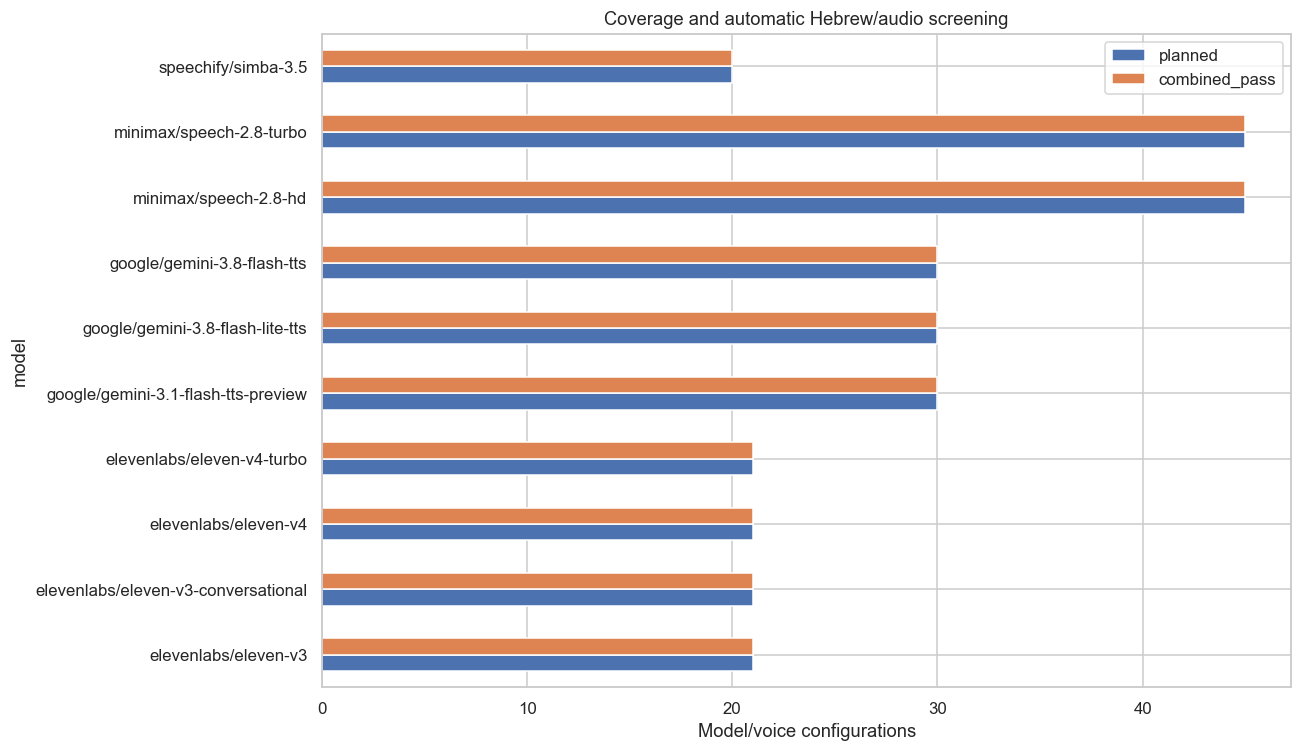

In [2]:
coverage=df.groupby(['family','model']).agg(planned=('sample_id','size'),generated=('generation_status',lambda s:s.isin(['generated','decoded']).sum()),decoded=('generation_status',lambda s:s.eq('decoded').sum()),technical_pass=('technical_qc_pass','sum'),automatic_hebrew_pass=('language_qc_pass','sum'),combined_pass=('pilot_automatic_qc_pass','sum'),seconds=('duration_s','sum')).reset_index()
coverage['minutes']=coverage.seconds/60
export(coverage,'model_coverage'); display(coverage)
missing=pd.DataFrame({'field':df.columns,'missing_or_blank':[int((df[c].isna()|df[c].eq('')).sum()) for c in df]})
export(missing,'missingness')
inventory=[]
for row in df.itertuples():
    for kind,relative,expected in [('original',getattr(row,'original_path',''),getattr(row,'original_sha256','')),('wav',getattr(row,'wav_path',''),getattr(row,'wav_sha256',''))]:
        if isinstance(relative,str) and relative:
            p=BASE/relative; actual=hashlib.sha256(p.read_bytes()).hexdigest() if p.is_file() else None
            inventory.append({'sample_id':row.sample_id,'kind':kind,'path':relative,'exists':p.is_file(),'bytes':p.stat().st_size if p.is_file() else 0,'sha256':actual,'matches_generation_hash':actual==expected})
inventory=pd.DataFrame(inventory); export(inventory,'file_inventory')
assert inventory.exists.all() and inventory.matches_generation_hash.all()
duplicates=df[df.wav_sha256.duplicated(False)].sort_values('wav_sha256')
export(duplicates,'exact_analysis_audio_duplicates')
overview={'planned_samples':len(planned),'attempted_samples':len(generated),'decoded_samples':int(df.generation_status.eq('decoded').sum()),'models':df.model.nunique(),'families':df.family.nunique(),'provider_voice_groups':df.voice_identity_group.nunique(),'minutes_generated':float(df.duration_s.sum()/60),'technical_qc_pass':int(df.technical_qc_pass.sum()),'automatic_hebrew_match_pass':int(df.language_qc_pass.sum()),'combined_qc_pass':int(df.pilot_automatic_qc_pass.sum()),'human_verified_samples':0,'exact_pcm_duplicate_recordings':len(duplicates)}
display(pd.Series(overview).to_frame('value'))
ax=coverage.set_index('model')[['planned','combined_pass']].plot.barh(figsize=(12,7)); ax.set(xlabel='Model/voice configurations',title='Coverage and automatic Hebrew/audio screening'); savefig('coverage')


## Provider labels and perceptual estimates
Provider gender/age labels are read only from retrievable official metadata, not guessed from names. Audio-model outputs are subjective, not calibrated probabilities. For the displayed perceptual summaries, confidence below 0.6 becomes uncertain. Conflicting estimates for the same provider/voice across model versions are explicitly marked.

The review model transcribes the audio independently of the intended text. It also judges perceived casting age, but these estimates remain unvalidated: the model has not been calibrated on Hebrew voices with human ratings. They must not be interpreted as demographic ground truth.

,voice_identity_group,family,voice,configurations,valid_configurations,provider_gender_label,provider_age_label,perceived_presentation,perceived_age_band
0,elevenlabs:adam,elevenlabs,adam,4,4,male,middle_aged,masculine,uniform_estimator_not_validated
1,elevenlabs:alice,elevenlabs,alice,4,4,female,middle_aged,conflicting_across_models,uniform_estimator_not_validated
2,elevenlabs:bella,elevenlabs,bella,4,4,female,middle_aged,masculine,uniform_estimator_not_validated
3,elevenlabs:bill,elevenlabs,bill,4,4,male,old,masculine,uniform_estimator_not_validated
4,elevenlabs:brian,elevenlabs,brian,4,4,male,middle_aged,conflicting_across_models,uniform_estimator_not_validated
5,elevenlabs:callum,elevenlabs,callum,4,4,male,middle_aged,masculine,uniform_estimator_not_validated
6,elevenlabs:charlie,elevenlabs,charlie,4,4,male,young,masculine,uniform_estimator_not_validated
7,elevenlabs:chris,elevenlabs,chris,4,4,male,middle_aged,masculine,uniform_estimator_not_validated
8,elevenlabs:daniel,elevenlabs,daniel,4,4,male,middle_aged,masculine,uniform_estimator_not_validated
9,elevenlabs:eric,elevenlabs,eric,4,4,male,middle_aged,masculine,uniform_estimator_not_validated


,unit,field,category,count,denominator,pct
0,model_voice_configurations,presentation_for_summary,masculine,212,284,74.647887
1,model_voice_configurations,presentation_for_summary,feminine,72,284,25.352113
2,model_voice_configurations,age_for_summary,uniform_estimator_not_validated,284,284,100.000000
3,provider_voice_groups,perceived_presentation,masculine,67,116,57.758621
4,provider_voice_groups,perceived_presentation,conflicting_across_models,35,116,30.172414
5,provider_voice_groups,perceived_presentation,feminine,14,116,12.068966
6,provider_voice_groups,perceived_age_band,uniform_estimator_not_validated,116,116,100.000000
7,provider_voice_groups,provider_gender_label,unknown,95,116,81.896552
8,provider_voice_groups,provider_gender_label,male,13,116,11.206897
9,provider_voice_groups,provider_gender_label,female,7,116,6.034483


,raw_model_age_category,configurations
0,adult_30_44,284


**Age estimation failed an informativeness check:** the audio model assigned every reviewed clip the same age category. This is not accepted as an age distribution. Use provider labels where supplied and human listening ratings; raw model outputs remain in the audit.

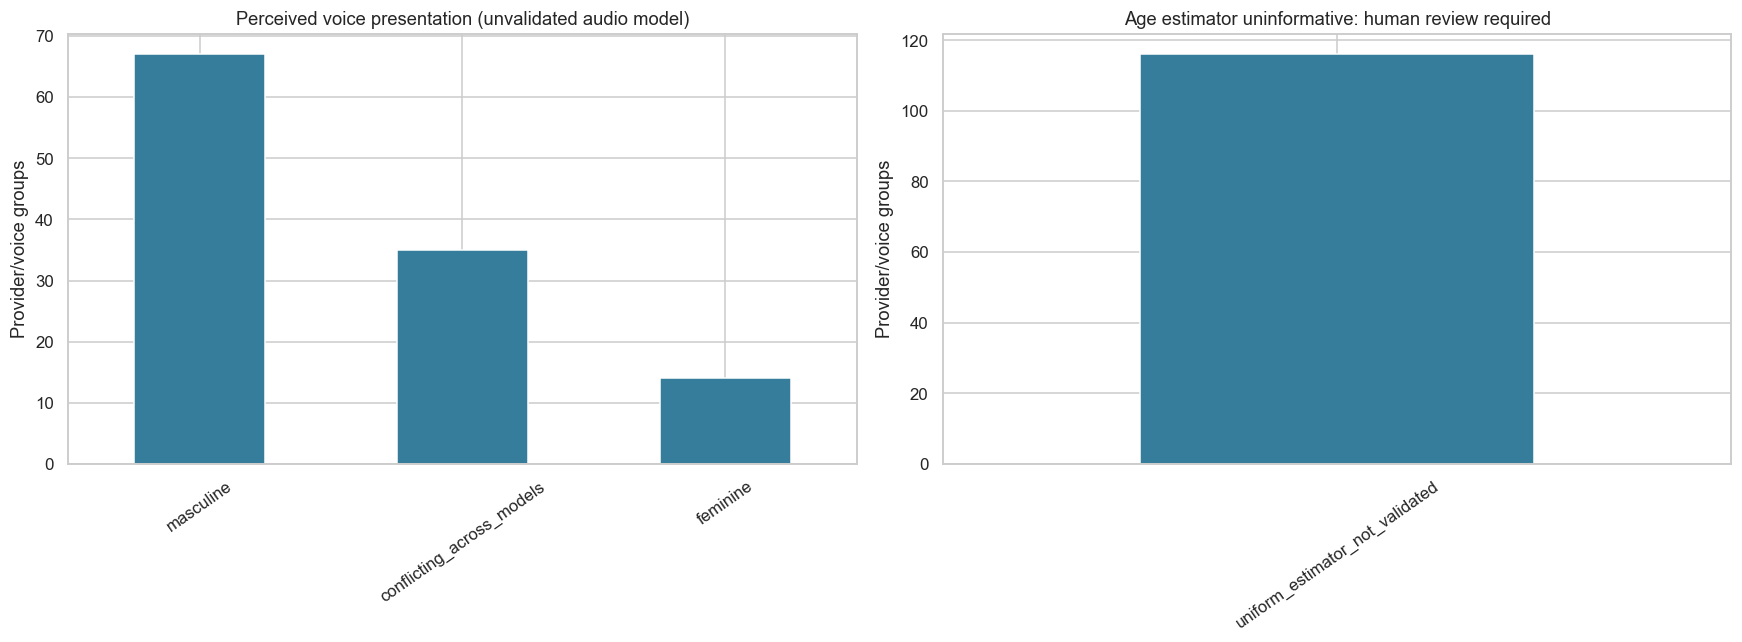

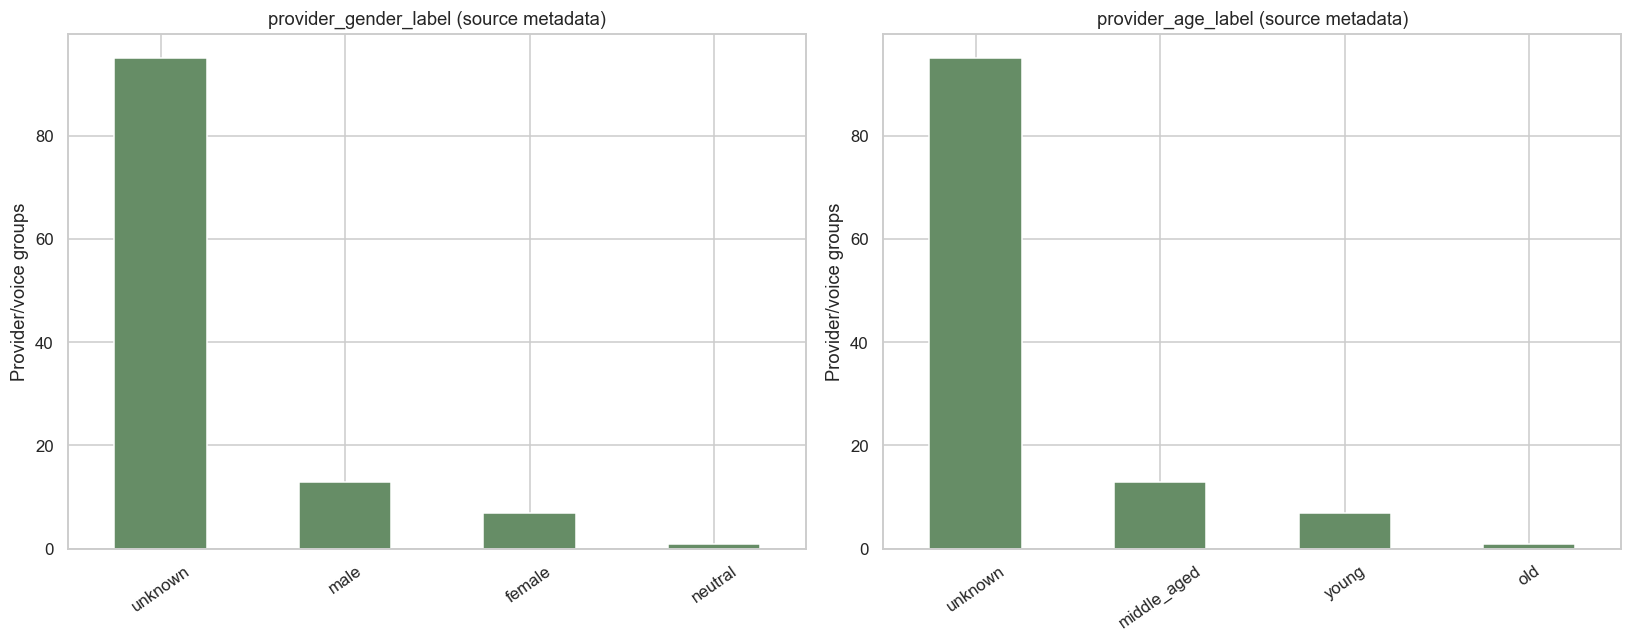

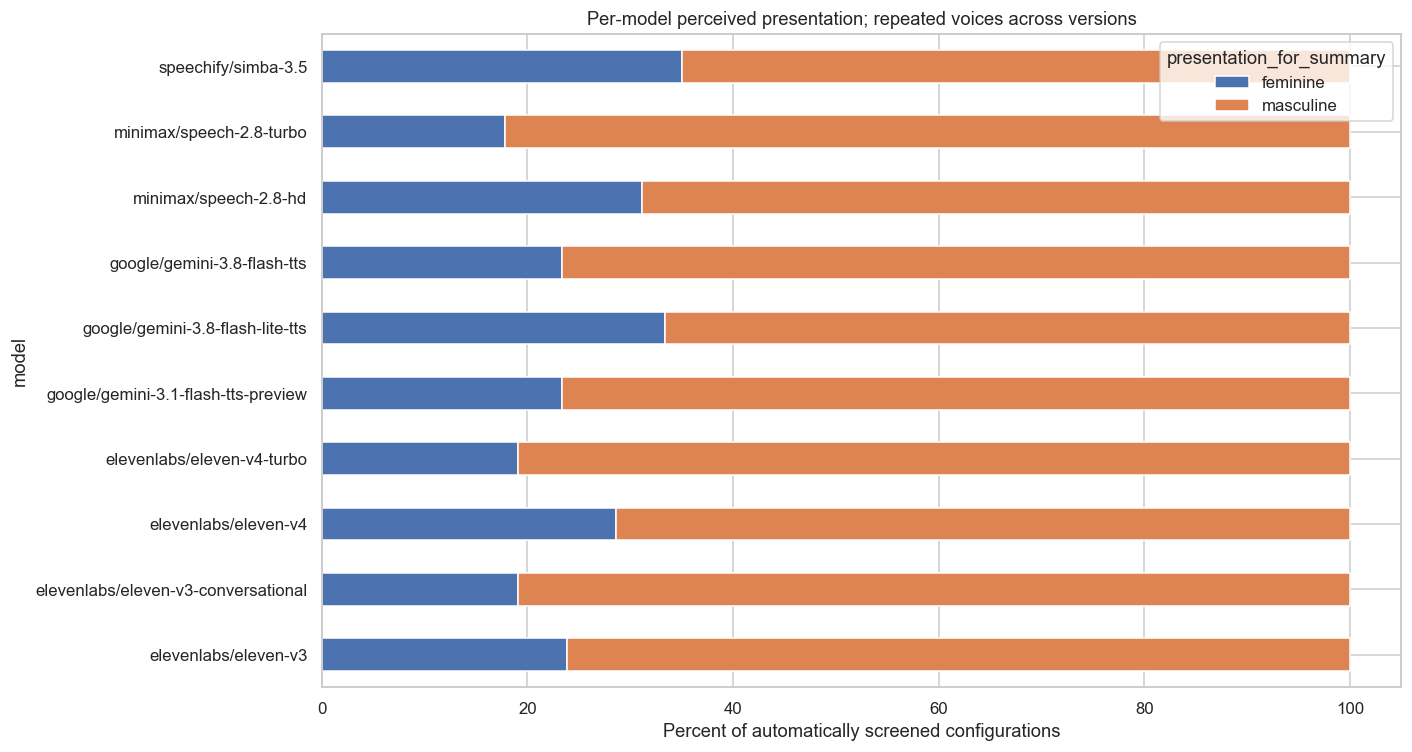

In [3]:
valid=df[df.pilot_automatic_qc_pass].copy()
def conservative_category(series):
    values=set(series.dropna().replace('','uncertain'))
    known=values-{'uncertain'}
    if len(known)>1: return 'conflicting_across_models'
    if 'uncertain' in values or not known: return 'uncertain'
    return next(iter(known))
def source_category(series):
    values=set(series.fillna('unknown').replace('','unknown'))
    return next(iter(values)) if len(values)==1 else 'conflicting_provider_labels'
voices=[]
for identity,g in df.groupby('voice_identity_group'):
    good=g[g.pilot_automatic_qc_pass]
    voices.append({'voice_identity_group':identity,'family':g.family.iloc[0],'voice':g.voice.iloc[0],
                   'configurations':len(g),'valid_configurations':len(good),
                   'provider_gender_label':source_category(g.provider_gender_label),
                   'provider_age_label':source_category(g.provider_age_label),
                   'perceived_presentation':conservative_category(good.presentation_for_summary) if len(good) else 'not_validated',
                   'perceived_age_band':conservative_category(good.age_for_summary) if len(good) else 'not_validated'})
voice_summary=pd.DataFrame(voices); export(voice_summary,'voice_summary'); display(voice_summary.head(15))
distributions=[]
for unit,frame,fields in [('model_voice_configurations',valid,['presentation_for_summary','age_for_summary']),('provider_voice_groups',voice_summary,['perceived_presentation','perceived_age_band','provider_gender_label','provider_age_label'])]:
    for field in fields:
        counts=frame[field].value_counts(dropna=False)
        for value,count in counts.items(): distributions.append({'unit':unit,'field':field,'category':value,'count':int(count),'denominator':len(frame),'pct':100*count/len(frame) if len(frame) else np.nan})
distributions=pd.DataFrame(distributions); export(distributions,'voice_distributions'); display(distributions)
raw_age=df.raw_age_for_summary.value_counts().rename_axis('raw_model_age_category').reset_index(name='configurations'); export(raw_age,'raw_age_model_outputs'); display(raw_age)
if age_estimator_uninformative: display(Markdown('**Age estimation failed an informativeness check:** the audio model assigned every reviewed clip the same age category. This is not accepted as an age distribution. Use provider labels where supplied and human listening ratings; raw model outputs remain in the audit.'))
fig,axes=plt.subplots(1,2,figsize=(16,6))
for ax,field,title in [(axes[0],'perceived_presentation','Perceived voice presentation (unvalidated audio model)'),(axes[1],'perceived_age_band','Age estimator uninformative: human review required' if age_estimator_uninformative else 'Perceived casting age (unvalidated; not actual age)')]:
    voice_summary[field].value_counts().plot.bar(ax=ax,color='#367d9c'); ax.set(title=title,ylabel='Provider/voice groups',xlabel=''); ax.tick_params(axis='x',labelrotation=35)
savefig('perceptual_voice_groups')
fig,axes=plt.subplots(1,2,figsize=(15,6))
for ax,field in zip(axes,['provider_gender_label','provider_age_label']):
    voice_summary[field].value_counts().plot.bar(ax=ax,color='#668d66'); ax.set(title=field+' (source metadata)',ylabel='Provider/voice groups',xlabel=''); ax.tick_params(axis='x',labelrotation=35)
savefig('provider_labels')
fig,ax=plt.subplots(figsize=(13,7)); pd.crosstab(valid.model,valid.presentation_for_summary,normalize='index').mul(100).plot.barh(stacked=True,ax=ax); ax.set(title='Per-model perceived presentation; repeated voices across versions',xlabel='Percent of automatically screened configurations'); savefig('presentation_by_model')


## Acoustic distributions and outlier candidates
Analysis uses 16 kHz mono WAV, 20 ms nonoverlapping energy frames and a -45 dBFS quiet threshold. Quiet frames are not VAD. Energy dynamic range is not calibrated SNR. Near-full-scale samples are clipping candidates, not proof of clipping. Nominal prompt WPM assumes the intended words were spoken; use only with transcript checks and do not interpret it as independently measured speaking rate.

,feature,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
0,duration_s,284.0,4.671870,0.675452,3.360000,3.746400,3.850125,4.160000,4.519750,5.005875,6.000000,6.450025,8.240000
1,rms_dbfs,284.0,-20.501600,4.507263,-44.707436,-36.247686,-28.209263,-22.713473,-19.531190,-17.481101,-14.877273,-14.095752,-13.610990
2,peak,284.0,0.668028,0.232888,0.059927,0.132425,0.282596,0.494537,0.705314,0.854216,1.011677,1.032502,1.039295
3,quiet_fraction_45dbfs,284.0,0.160232,0.067460,0.041667,0.051903,0.068165,0.116823,0.164103,0.194833,0.237804,0.425122,0.615385
4,energy_dynamic_range_db,284.0,41.321956,12.877311,18.244651,18.903094,21.015046,30.338433,42.770404,51.181383,60.253313,68.681765,71.639738
5,near_fullscale_fraction,284.0,0.000010,0.000050,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000034,0.000253,0.000570
6,dc_offset,284.0,-0.000136,0.000393,-0.002697,-0.000851,-0.000648,-0.000435,-0.000075,0.000116,0.000369,0.000747,0.001869
7,nominal_prompt_wpm,284.0,104.659658,13.562556,58.252427,74.422688,80.000000,95.887728,106.200565,115.384615,124.676104,128.131360,142.857143


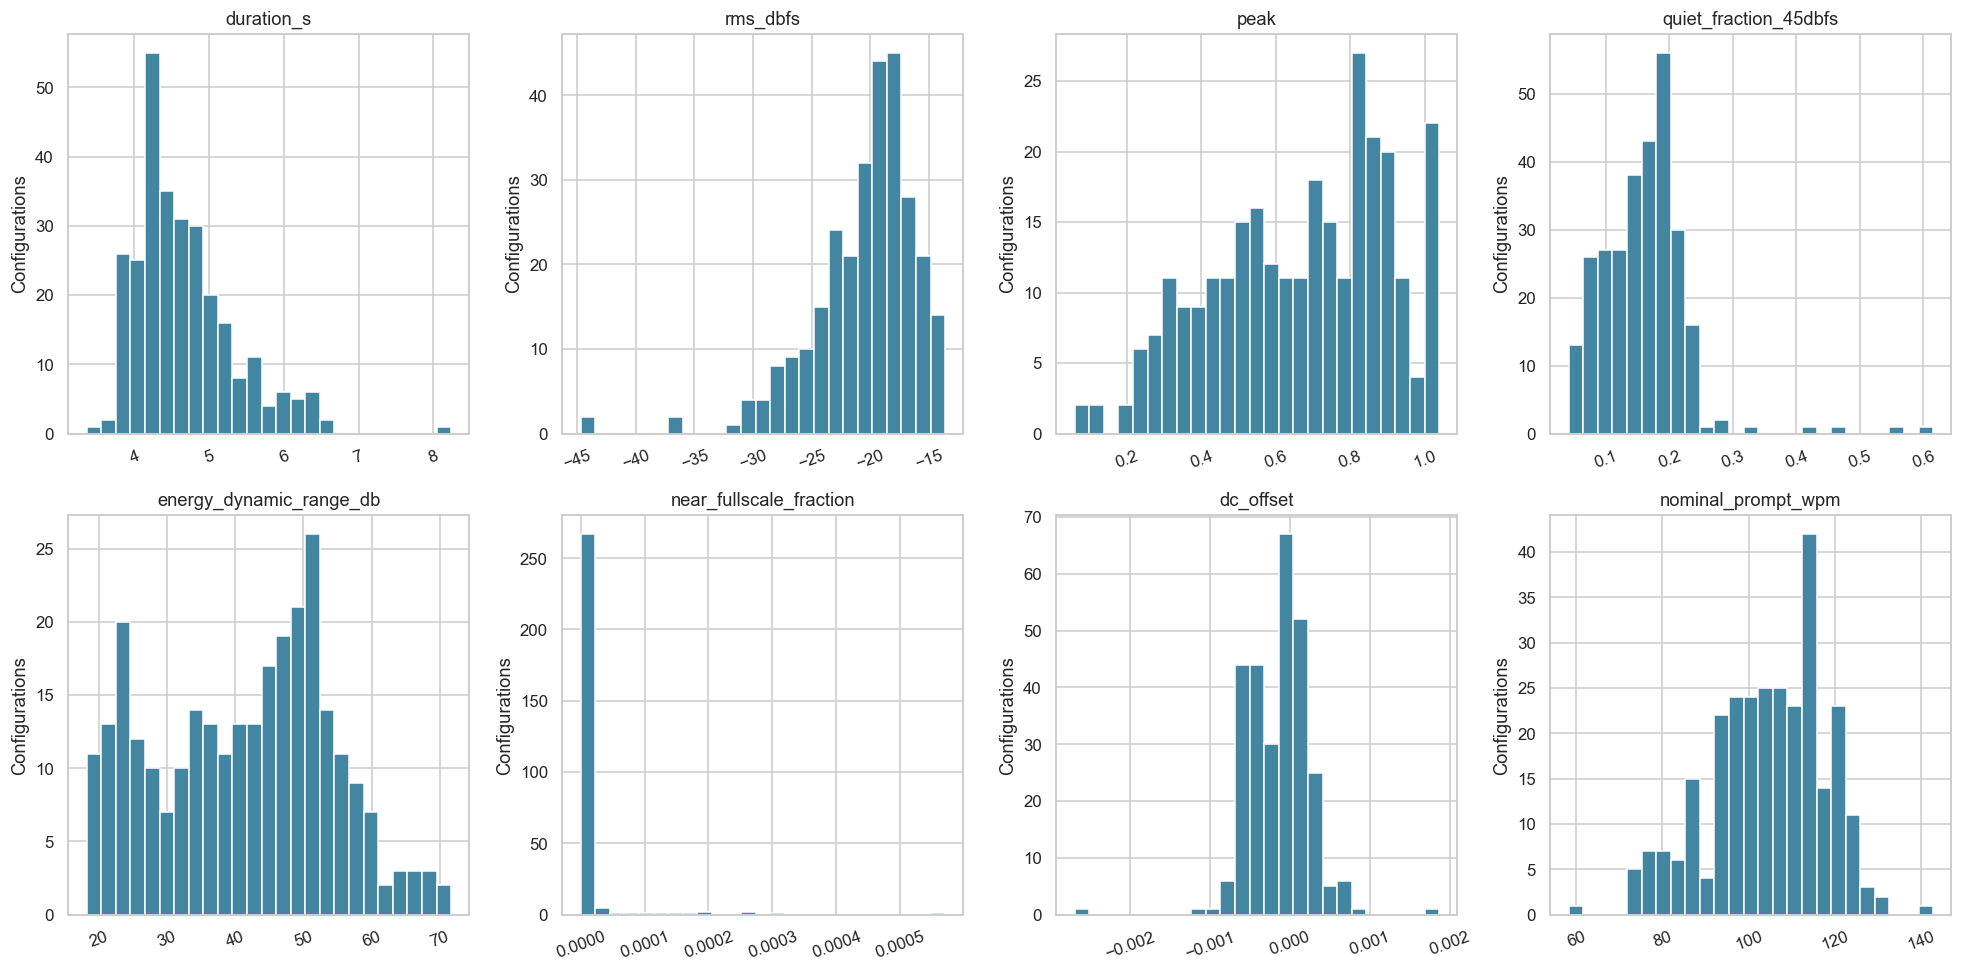

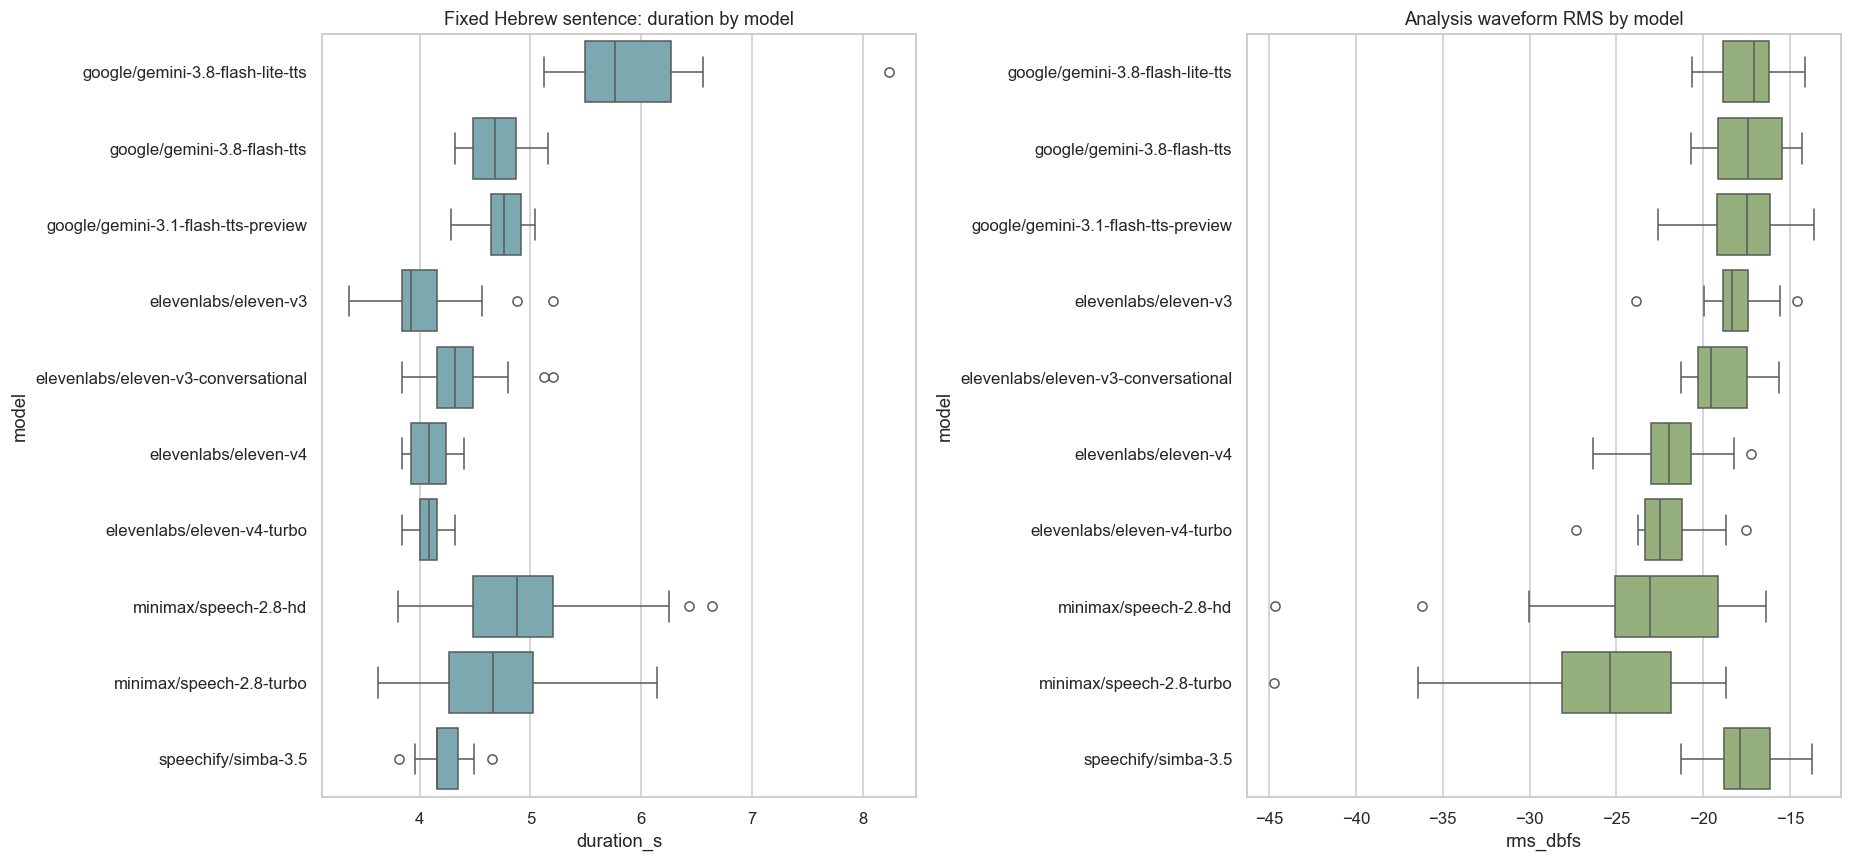

,model,voice,review_reasons
185,minimax/speech-2.8-hd,English_Whispering_girl,quiet_majority;low_rms;outlier_rms_dbfs;outlie...
230,minimax/speech-2.8-turbo,English_Whispering_girl,quiet_majority;low_rms;outlier_rms_dbfs;outlie...
192,minimax/speech-2.8-hd,English_FriendlyPerson,outlier_rms_dbfs;outlier_quiet_fraction_45dbfs
237,minimax/speech-2.8-turbo,English_FriendlyPerson,outlier_rms_dbfs;outlier_quiet_fraction_45dbfs
12,google/gemini-3.8-flash-lite-tts,Umbriel,outlier_duration_s
21,google/gemini-3.8-flash-lite-tts,Schedar,outlier_duration_s
209,minimax/speech-2.8-hd,English_PatientMan,outlier_duration_s


In [4]:
metrics=['duration_s','rms_dbfs','peak','quiet_fraction_45dbfs','energy_dynamic_range_db','near_fullscale_fraction','dc_offset','nominal_prompt_wpm']
numeric=df[metrics].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T.reset_index(names='feature'); export(numeric,'numeric_summary'); display(numeric)
fig,axes=plt.subplots(2,4,figsize=(18,9))
for ax,field in zip(axes.flat,metrics): ax.hist(df[field].dropna(),bins=25,color='#4386a2'); ax.set(title=field,ylabel='Configurations'); ax.tick_params(axis='x',labelrotation=20)
savefig('acoustic_distributions')
fig,axes=plt.subplots(1,2,figsize=(17,8))
sns.boxplot(data=df,y='model',x='duration_s',ax=axes[0],color='#73b0b7'); axes[0].set_title('Fixed Hebrew sentence: duration by model')
sns.boxplot(data=df,y='model',x='rms_dbfs',ax=axes[1],color='#94b973'); axes[1].set_title('Analysis waveform RMS by model'); savefig('model_audio_comparison')
flag=pd.DataFrame({'sample_id':df.sample_id})
flag['technical_fail']=~df.technical_qc_pass
flag['hebrew_text_match_needs_review']=~df.language_qc_pass
flag['quiet_majority']=df.quiet_fraction_45dbfs>.5
flag['near_fullscale_candidate']=df.near_fullscale_fraction>.001
flag['low_rms']=df.rms_dbfs< -40
rules=[]
for field in ['duration_s','rms_dbfs','quiet_fraction_45dbfs','energy_dynamic_range_db']:
    x=df[field]; median=x.median(); mad=(x-median).abs().median(); q1,q3=x.quantile([.25,.75]); iqr=q3-q1
    if mad>0: flagged=(.6745*(x-median)/mad).abs()>3.5; method='modified_z_abs_gt_3.5'
    elif iqr>0: flagged=(x<q1-1.5*iqr)|(x>q3+1.5*iqr); method='IQR_1.5_fallback'
    else: flagged=pd.Series(False,index=x.index); method='degenerate_no_flag'
    flag['outlier_'+field]=flagged.fillna(False)
    rules.append({'feature':field,'median':median,'MAD':mad,'IQR':iqr,'method':method,'flagged':int(flagged.sum())})
export(pd.DataFrame(rules),'outlier_rules'); export(flag,'sample_flags')
df['review_flag_count']=flag.drop(columns='sample_id').sum(axis=1)
df['review_reasons']=flag.drop(columns='sample_id').apply(lambda row:';'.join(row.index[row.astype(bool)]),axis=1)
review_candidates=df[df.review_flag_count>0].sort_values('review_flag_count',ascending=False); export(review_candidates,'review_candidates')
display(review_candidates[['model','voice','review_reasons']].head(20))


## Hebrew content checks and human-speech reference
The normalized character edit distance compares an audio-model transcription to the intended sentence; it is not gold-standard ASR CER. Numeric/spelling alternatives can create differences even when speech is correct. Automatic passage requires Hebrew language identification, at least 80% Hebrew letters in the transcription, normalized edit distance <= 0.25, and model intelligibility >= 0.7. Every accepted clip still permits human correction.

The human reference has one short 6-10-word excerpt per eligible recorder, selected at 3-8 seconds, within the first 20 seconds of a source recording with alignment confidence >=0.8. It spans fewer than all 85 recorders because these are explicit eligibility rules. Both references and synthetic clips use 16 kHz mono analysis. Text, channel history and selection differ, so comparisons are descriptive and cannot isolate a synthesis effect.

,model,configurations,reviewed,automatic_hebrew_match,median_transcript_distance
0,elevenlabs/eleven-v3,21,21,21,0.113636
1,elevenlabs/eleven-v3-conversational,21,21,21,0.113636
2,elevenlabs/eleven-v4,21,21,21,0.113636
3,elevenlabs/eleven-v4-turbo,21,21,21,0.113636
4,google/gemini-3.1-flash-tts-preview,30,30,30,0.022727
5,google/gemini-3.8-flash-lite-tts,30,30,30,0.022727
6,google/gemini-3.8-flash-tts,30,30,30,0.022727
7,minimax/speech-2.8-hd,45,45,45,0.022727
8,minimax/speech-2.8-turbo,45,45,45,0.113636
9,speechify/simba-3.5,20,20,20,0.022727


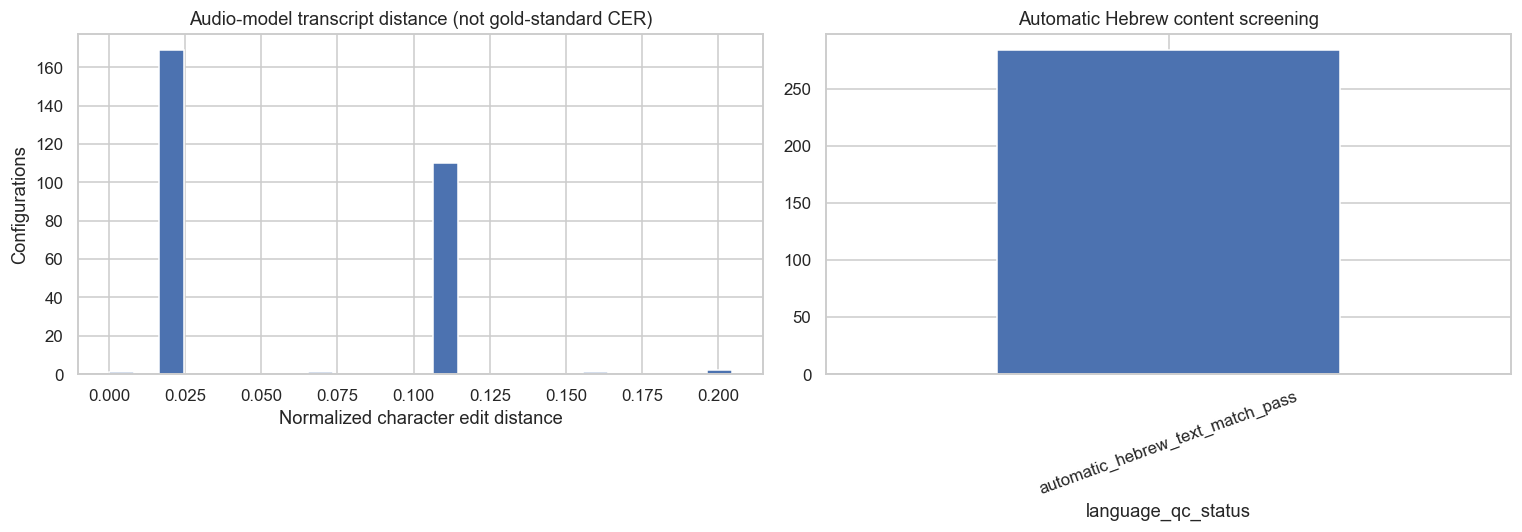

,source,duration_s_count,duration_s_median,duration_s_mean,duration_s_std,rms_dbfs_count,rms_dbfs_median,rms_dbfs_mean,rms_dbfs_std,quiet_fraction_45dbfs_count,quiet_fraction_45dbfs_median,quiet_fraction_45dbfs_mean,quiet_fraction_45dbfs_std,energy_dynamic_range_db_count,energy_dynamic_range_db_median,energy_dynamic_range_db_mean,energy_dynamic_range_db_std
0,Real utterance reference,78,3.67000,3.847821,0.800352,78,-22.247754,-21.623162,3.838248,78,0.116335,0.124933,0.081403,78,28.707379,34.737151,25.961446
1,Synthetic fixed utterance,284,4.51975,4.671870,0.675452,284,-19.531190,-20.501600,4.507263,284,0.164103,0.160232,0.067460,284,42.770404,41.321956,12.877311


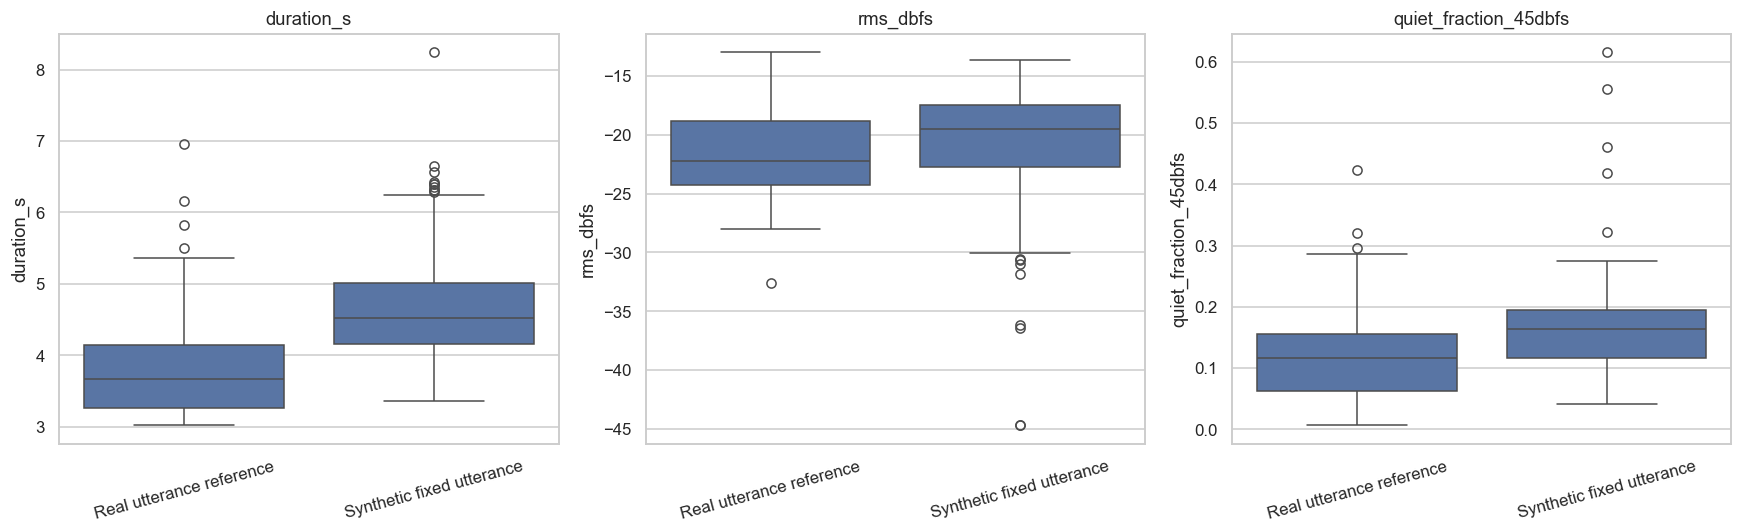

In [5]:
language=df.groupby('model').agg(configurations=('sample_id','size'),reviewed=('review_status',lambda s:s.eq('reviewed').sum()),automatic_hebrew_match=('language_qc_pass','sum'),median_transcript_distance=('normalized_character_error_rate','median')).reset_index()
export(language,'hebrew_validation'); display(language)
language_failed=df[~df.language_qc_pass]; export(language_failed,'hebrew_review_candidates')
fig,axes=plt.subplots(1,2,figsize=(14,5)); axes[0].hist(df.normalized_character_error_rate.dropna(),bins=25); axes[0].set(title='Audio-model transcript distance (not gold-standard CER)',xlabel='Normalized character edit distance',ylabel='Configurations'); df.language_qc_status.fillna('not_reviewed').value_counts().plot.bar(ax=axes[1]); axes[1].set_title('Automatic Hebrew content screening'); axes[1].tick_params(axis='x',labelrotation=20); savefig('hebrew_screening')
human=pd.read_csv(BASE/'human_reference.csv'); human=human[human.reference_status.eq('decoded')].copy()
comparison=pd.concat([human[['duration_s','rms_dbfs','quiet_fraction_45dbfs','energy_dynamic_range_db']].assign(source='Real utterance reference'),valid[['duration_s','rms_dbfs','quiet_fraction_45dbfs','energy_dynamic_range_db']].assign(source='Synthetic fixed utterance')])
comparison_summary=comparison.groupby('source').agg(['count','median','mean','std']).reset_index(); comparison_summary.columns=['_'.join(c).strip('_') if isinstance(c,tuple) else c for c in comparison_summary.columns]; export(comparison_summary,'real_synthetic_summary'); display(comparison_summary)
fig,axes=plt.subplots(1,3,figsize=(16,5))
for ax,field in zip(axes,['duration_s','rms_dbfs','quiet_fraction_45dbfs']): sns.boxplot(data=comparison,x='source',y=field,ax=ax); ax.set_title(field); ax.set_xlabel(''); ax.tick_params(axis='x',labelrotation=15)
savefig('real_synthetic_reference')


## Cost, conclusions and limits
Per-request reported costs are preferred to key usage snapshots, which can lag or fluctuate. A missing cost is not zero. Provider labels are not verified demographics, and audio-model perceived age/presentation estimates have no validated accuracy for this pilot. The listening workbench saves human ratings separately. One short example per configuration does not estimate within-voice variation, recording-session variation, naturalness reliability, or demographic representativeness.

In [6]:
billing=json.loads((BASE/'billing_summary.json').read_text(encoding='utf-8')) if (BASE/'billing_summary.json').exists() else {'billing_complete':False,'status':'pending'}
display(pd.Series(billing).to_frame('value'))
overview.update({'reference_speakers':int(human.user_id.nunique()),'review_candidates':len(review_candidates),'perceptual_presentation_conflicting_groups':int(voice_summary.perceived_presentation.eq('conflicting_across_models').sum()),'perceptual_age_conflicting_groups':int(voice_summary.perceived_age_band.eq('conflicting_across_models').sum()),'age_estimator_uninformative':age_estimator_uninformative,'billing':billing})
(ANALYSIS/'key_metrics.json').write_text(json.dumps(overview,indent=2),encoding='utf-8')
export(df,'sample_features')
baseline=df.groupby('voice_identity_group',group_keys=False).sample(n=1,random_state=20261116)
export(baseline[['sample_id','model','voice','voice_identity_group','wav_path']],'speaker_spanning_listening_sample')
perceived=distributions[(distributions.unit=='provider_voice_groups')&distributions.field.isin(['perceived_presentation','perceived_age_band'])]
report=f'''# Synthetic Hebrew voice pilot: findings and progress

## What was completed
{overview['decoded_samples']} of {overview['planned_samples']} planned configurations decoded successfully across {overview['models']} models, {overview['families']} provider families and {overview['provider_voice_groups']} nominal provider/voice groups. Generated audio totals {overview['minutes_generated']:.2f} minutes. Every request used the same Hebrew text: {planned.text.iloc[0]}

Original audio and derived analysis WAV have separate hashes. No reference-audio cloning or corpus-volume expansion occurred. The recorded stock-voice catalog, exact requests, generation IDs, billing records and failed review attempts are retained. Initial audio-review JSON-mode failures were diagnosed; after removing the incompatible parameter, explicit repair attempts were logged rather than silently replacing history.

## Coverage and Hebrew screening
{markdown_table(coverage)}

{overview['technical_qc_pass']} configurations passed technical screening and {overview['automatic_hebrew_match_pass']} passed automatic Hebrew/text screening. The combined passed count is {overview['combined_qc_pass']}. Language passage is an audio-model transcription/recognition check, not human verification; corrections remain possible in review.html. Failed or unverified clips remain in the manifest and are not counted as automatically accepted Hebrew samples.

## Perceptual voice groups — unvalidated estimates
{markdown_table(perceived)}

These are casting impressions from very short synthetic clips, not real ages, biological sex or verified gender identities. Below-0.6 self-confidence is mapped to uncertain. The model's confidence is not calibrated. {overview['perceptual_presentation_conflicting_groups']} nominal voice groups have conflicting presentation estimates across model versions. Do not hide those conflicts with majority voting. Source-provided voice labels are reported separately in provider_labels.png and voice_summary.csv.

Age estimator uninformative: **{age_estimator_uninformative}**. The audio model returned the same age category for all clips, including voices with different source age descriptions. This failed informativeness check prevents presenting those outputs as a usable age distribution. All raw estimates remain in raw_age_model_outputs.csv; perceived age requires human listening or a separately validated estimator.

## Acoustic patterns and outliers
The notebook includes numerical percentiles, model comparisons, quiet-frame fractions, waveform levels, format history, duplicate screening and robust outlier flags. There are {len(review_candidates)} configurations with one or more broad review flags. No recordings were deleted. Silence thresholds are not VAD, dynamic range is not SNR, and near-full-scale samples do not establish clipping. Repeated text is deliberate and lexical coverage is therefore fixed, unlike the real corpus.

## Real-speech reference
{len(human)} utterances from {human.user_id.nunique()} real recorder IDs were processed at the same analysis sample rate. Each was selected to be 3-8 seconds and 6-10 aligned words, with source alignment score >=0.8. They are not the same sentence and have different recording/channel histories. Comparisons must not be presented as proof of a synthesis effect or used to claim classifier accuracy. This subset is not a replacement for the full 85-recorder dataset.

## Costs
{json.dumps(billing,ensure_ascii=False,indent=2)}

Missing or incomplete billing is explicitly marked and must not be interpreted as free generation. API usage snapshots can be eventually consistent. The project limit remains $20; this pilot does not authorize spending the remaining balance on a 20-hour dataset.

## Next steps
Listen to review candidates and the seeded one-example-per-voice baseline. Rate perceived presentation, casting-age category, Hebrew correctness and intelligibility; export human ratings from the workbench. Double-rate a subset before treating perceptual labels as reliable. Choose text and voice/engine split rules before any training experiment, and retain the repeated-text pilot as a clearly tagged calibration/EDA subset. The four provider families are not proof of architectural independence, and models sharing voice identifiers are dependent.
'''
(ROOT/'SYNTHETIC_EDA_PROGRESS.md').write_text(report,encoding='utf-8')
provenance={'executed_utc':pd.Timestamp.now(tz='UTC').isoformat(),'python':sys.version,'versions':{name:importlib.metadata.version(name) for name in ['openai','numpy','pandas','av','nbformat','nbclient','matplotlib','seaborn']},'seed':20261116,'metrics':overview,'input_sha256':{name:hashlib.sha256((BASE/name).read_bytes()).hexdigest() for name in ['planned_samples.csv','manifest.csv','automated_review.json','catalog_snapshot.json']}}
(ANALYSIS/'provenance.json').write_text(json.dumps(provenance,indent=2),encoding='utf-8')
display(Markdown(report))
assert len(df)==len(planned) and set(generated.sample_id)==set(planned.sample_id)
assert len(voice_summary)==planned.voice_identity_group.nunique()
print('Exports:',len(list(ANALYSIS.glob('*.csv'))),'CSV tables;',len(list(FIG.glob('*.png'))),'figures')


,value
checked_utc,2026-11-16T19:50:06.800093+00:00
speech_requests_with_cost,284
speech_requests_total,284
reported_speech_cost_usd,0.695038
audio_reviews_with_cost,284
reported_review_cost_usd,0.130199
latest_key_usage_delta_usd,0.817032
billing_complete,True
key_usage_note,Key usage may lag and fluctuate between cached...
reported_request_cost_sum_usd,0.825237


# Synthetic Hebrew voice pilot: findings and progress

## What was completed
284 of 284 planned configurations decoded successfully across 10 models, 4 provider families and 116 nominal provider/voice groups. Generated audio totals 22.11 minutes. Every request used the same Hebrew text: היום ניפגש בשעה שלוש ליד תחנת הרכבת בירושלים.

Original audio and derived analysis WAV have separate hashes. No reference-audio cloning or corpus-volume expansion occurred. The recorded stock-voice catalog, exact requests, generation IDs, billing records and failed review attempts are retained. Initial audio-review JSON-mode failures were diagnosed; after removing the incompatible parameter, explicit repair attempts were logged rather than silently replacing history.

## Coverage and Hebrew screening
| family | model | planned | generated | decoded | technical_pass | automatic_hebrew_pass | combined_pass | seconds | minutes |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| elevenlabs | elevenlabs/eleven-v3 | 21 | 21 | 21 | 21 | 21 | 21 | 85.44 | 1.424 |
| elevenlabs | elevenlabs/eleven-v3-conversational | 21 | 21 | 21 | 21 | 21 | 21 | 91.68 | 1.528 |
| elevenlabs | elevenlabs/eleven-v4 | 21 | 21 | 21 | 21 | 21 | 21 | 85.92 | 1.432 |
| elevenlabs | elevenlabs/eleven-v4-turbo | 21 | 21 | 21 | 21 | 21 | 21 | 85.92 | 1.432 |
| google | google/gemini-3.1-flash-tts-preview | 30 | 30 | 30 | 30 | 30 | 30 | 142.24 | 2.371 |
| google | google/gemini-3.8-flash-lite-tts | 30 | 30 | 30 | 30 | 30 | 30 | 176.08 | 2.935 |
| google | google/gemini-3.8-flash-tts | 30 | 30 | 30 | 30 | 30 | 30 | 140.36 | 2.339 |
| minimax | minimax/speech-2.8-hd | 45 | 45 | 45 | 45 | 45 | 45 | 221.413 | 3.69 |
| minimax | minimax/speech-2.8-turbo | 45 | 45 | 45 | 45 | 45 | 45 | 213.278 | 3.555 |
| speechify | speechify/simba-3.5 | 20 | 20 | 20 | 20 | 20 | 20 | 84.48 | 1.408 |

284 configurations passed technical screening and 284 passed automatic Hebrew/text screening. The combined passed count is 284. Language passage is an audio-model transcription/recognition check, not human verification; corrections remain possible in review.html. Failed or unverified clips remain in the manifest and are not counted as automatically accepted Hebrew samples.

## Perceptual voice groups — unvalidated estimates
| unit | field | category | count | denominator | pct |
| --- | --- | --- | --- | --- | --- |
| provider_voice_groups | perceived_presentation | masculine | 67 | 116 | 57.759 |
| provider_voice_groups | perceived_presentation | conflicting_across_models | 35 | 116 | 30.172 |
| provider_voice_groups | perceived_presentation | feminine | 14 | 116 | 12.069 |
| provider_voice_groups | perceived_age_band | uniform_estimator_not_validated | 116 | 116 | 100.0 |

These are casting impressions from very short synthetic clips, not real ages, biological sex or verified gender identities. Below-0.6 self-confidence is mapped to uncertain. The model's confidence is not calibrated. 35 nominal voice groups have conflicting presentation estimates across model versions. Do not hide those conflicts with majority voting. Source-provided voice labels are reported separately in provider_labels.png and voice_summary.csv.

Age estimator uninformative: **True**. The audio model returned the same age category for all clips, including voices with different source age descriptions. This failed informativeness check prevents presenting those outputs as a usable age distribution. All raw estimates remain in raw_age_model_outputs.csv; perceived age requires human listening or a separately validated estimator.

## Acoustic patterns and outliers
The notebook includes numerical percentiles, model comparisons, quiet-frame fractions, waveform levels, format history, duplicate screening and robust outlier flags. There are 7 configurations with one or more broad review flags. No recordings were deleted. Silence thresholds are not VAD, dynamic range is not SNR, and near-full-scale samples do not establish clipping. Repeated text is deliberate and lexical coverage is therefore fixed, unlike the real corpus.

## Real-speech reference
78 utterances from 78 real recorder IDs were processed at the same analysis sample rate. Each was selected to be 3-8 seconds and 6-10 aligned words, with source alignment score >=0.8. They are not the same sentence and have different recording/channel histories. Comparisons must not be presented as proof of a synthesis effect or used to claim classifier accuracy. This subset is not a replacement for the full 85-recorder dataset.

## Costs
{
  "checked_utc": "2026-11-16T19:50:06.800093+00:00",
  "speech_requests_with_cost": 284,
  "speech_requests_total": 284,
  "reported_speech_cost_usd": 0.695038,
  "audio_reviews_with_cost": 284,
  "reported_review_cost_usd": 0.1301988,
  "latest_key_usage_delta_usd": 0.8170324,
  "billing_complete": true,
  "key_usage_note": "Key usage may lag and fluctuate between cached snapshots; per-request records are preferred.",
  "reported_request_cost_sum_usd": 0.8252368000000001
}

Missing or incomplete billing is explicitly marked and must not be interpreted as free generation. API usage snapshots can be eventually consistent. The project limit remains $20; this pilot does not authorize spending the remaining balance on a 20-hour dataset.

## Next steps
Listen to review candidates and the seeded one-example-per-voice baseline. Rate perceived presentation, casting-age category, Hebrew correctness and intelligibility; export human ratings from the workbench. Double-rate a subset before treating perceptual labels as reliable. Choose text and voice/engine split rules before any training experiment, and retain the repeated-text pilot as a clearly tagged calibration/EDA subset. The four provider families are not proof of architectural independence, and models sharing voice identifiers are dependent.


Exports: 16 CSV tables; 8 figures
